# Neural networks from scratch
## Classification and regression with clearly separated functions

We build a network with one hidden layer and one output neuron. These are the two layers with trainable weights; the input is not counted as a trainable layer.

Only Python's standard library is used for the model. Matplotlib supplies the plots. No classes, automatic differentiation, or machine-learning libraries are used.

### Notebook roadmap
1. Build the model: `build_model`
2. Compute a prediction: `forward_propagation`
3. Measure error: `calculate_loss`
4. Compute derivatives: `backpropagation`
5. Update parameters: `update_parameters`
6. Repeat the learning steps: `train_model`
7. Evaluate and visualize results
8. Example A: binary classification
9. Example B: regression, comparing small and larger hidden layers

Each function appears directly after its explanation. The example sections show how the functions fit together.

In [1]:
import math
import random
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

## 1. Build the model

For two input features, hidden neuron $j$ begins with

$$z_j=w_{j1}x_1+w_{j2}x_2+b_j.$$

The hidden output is $h_j=\tanh(z_j)$. The output neuron combines the hidden outputs:

$$s=v_1h_1+v_2h_2+\cdots+v_mh_m+c.$$

We store four ordinary Python variables:
- `w[j][k]`: weight from input feature `k` to hidden neuron `j`;
- `b[j]`: bias of hidden neuron `j`;
- `v[j]`: weight from hidden neuron `j` to the output;
- `c`: output bias.

Math indices start at 1; Python indices start at 0. `build_model` initializes these variables and returns them. Random, unequal weights let different hidden neurons learn different responses.

In [2]:
def build_model(number_of_inputs, number_of_hidden_neurons, seed=9):
    """Return input weights w, hidden biases b, output weights v, and bias c."""
    rng = random.Random(seed)
    w = []
    for j in range(number_of_hidden_neurons):
        weights_for_neuron = []
        for k in range(number_of_inputs):
            weights_for_neuron.append(rng.uniform(-0.7, 0.7))
        w.append(weights_for_neuron)
    b = [rng.uniform(-0.2, 0.2) for j in range(number_of_hidden_neurons)]
    v = [rng.uniform(-0.7, 0.7) for j in range(number_of_hidden_neurons)]
    c = rng.uniform(-0.2, 0.2)
    return w, b, v, c

## 2. Forward propagation

For one observation, compute each hidden activation and then the output score:

$$z_j=b_j+\sum_{k=1}^{d}w_{jk}x_k,\qquad h_j=\tanh(z_j),\qquad s=c+\sum_{j=1}^{m}v_jh_j.$$

Classification uses a sigmoid to turn the score into a probability:

$$\hat y=\frac{1}{1+e^{-s}}.$$

Regression uses $\hat y=s$ so the prediction can be any real number. Return both the prediction and hidden activations: the backward pass needs the hidden activations.

In [3]:
def forward_propagation(x, w, b, v, c, task):
    """Predict one observation and return its hidden activations for backpropagation."""
    hidden = []
    for j in range(len(b)):
        # Add up the weighted sum w/ bias for each hidden neuron.
        z = b[j]

        for k in range(len(x)):
            z += w[j][k] * x[k]

        # Activation function applied after each weighted sum.
        hidden.append(math.tanh(z))

    # Output layer: weighted sum w/ bias
    score = c
    for j in range(len(hidden)):
        score += v[j] * hidden[j]

    # Depending on the task, may use activation function on output layer.
    if task == 'classification':
        if score >= 0:
            prediction = 1 / (1 + math.exp(-score))
        else:
            exponential = math.exp(score)
            prediction = exponential / (1 + exponential)
    elif task == 'regression':
        prediction = score
    else:
        raise ValueError('Choose classification or regression.')
    return prediction, hidden

## 3. Calculate the loss

For one binary-classification observation, binary cross-entropy is

$$\ell=-y\log(\hat y)-(1-y)\log(1-\hat y).$$

For regression, use half squared error:

$$\ell=\frac12(\hat y-y)^2.$$

Average these losses across the observations:

$$L=\frac1N\sum_{i=1}^{N}\ell_i.$$

The factor $1/2$ simplifies derivatives; this regression loss is half of the usual MSE. Validation observations are used for measuring loss, not computing parameter updates.

In [4]:
def calculate_loss(X, targets, w, b, v, c, task):
    """Return average binary cross-entropy or half mean squared error."""
    total = 0.0

    # Go through each sample and calculate the loss for that sample.
    for x, target in zip(X, targets):

        # Make a prediction
        prediction, hidden = forward_propagation(x, w, b, v, c, task)

        if task == 'classification':
            # Binary Cross-Entropy Loss with upper and lower bounds to avoid log(0).
            probability = min(max(prediction, 1e-12), 1 - 1e-12)
            total += -target * math.log(probability) - (1-target) * math.log(1-probability)
        else:
            # Mean Squared Error (MSE) Loss
            total += 0.5 * (prediction - target)**2
            
    return total / len(targets) # Take the average loss over all samples.

## 4. Backpropagation: derivatives, not updates

For sigmoid plus binary cross-entropy, the derivative with respect to output score is

$$\frac{\partial\ell}{\partial s}=\hat y-y.$$

For a linear output plus half squared error, the same expression follows. Define $\delta_{\mathrm{out}}=\hat y-y$.

### Output-layer derivatives
$$\frac{\partial\ell}{\partial v_j}=\delta_{\mathrm{out}}h_j,\qquad \frac{\partial\ell}{\partial c}=\delta_{\mathrm{out}}.$$

### Hidden-layer derivatives
Apply the chain rule to the path from a hidden neuron to the loss:

$$\delta_j=\frac{\partial\ell}{\partial z_j}=\delta_{\mathrm{out}}v_j(1-h_j^2).$$

Here $1-h_j^2$ is the derivative of $\tanh(z_j)$. Therefore,

$$\frac{\partial\ell}{\partial w_{jk}}=\delta_jx_k,\qquad\frac{\partial\ell}{\partial b_j}=\delta_j.$$

`backpropagation` averages these derivatives over the training data. It does not change the parameters. All derivatives use the same pre-update weights.

In [5]:
def backpropagation(X, targets, w, b, v, c, task):
    """Compute average training gradients; leave all model parameters unchanged."""
    # Fill in zero for all gradients to start.
    dw = [[0.0 for weight in row] for row in w]
    db = [0.0 for bias in b]
    dv = [0.0 for weight in v]
    dc = 0.0

    # Go through each sample and calculate the gradients for that sample.
    for x, target in zip(X, targets):
        prediction, hidden = forward_propagation(x, w, b, v, c, task)

        # Get difference between prediction and target for output layer.
        delta_out = prediction - target
        dc += delta_out

        # Accumulate gradients for output weights and hidden layer.
        for j in range(len(hidden)):
            dv[j] += delta_out * hidden[j]
            delta_hidden = delta_out * v[j] * (1 - hidden[j]**2)
            db[j] += delta_hidden
            for k in range(len(x)):
                dw[j][k] += delta_hidden * x[k]

    # Average the gradients over all samples.
    n = len(targets)
    for j in range(len(b)):
        db[j] /= n
        dv[j] /= n
        for k in range(len(w[j])):
            dw[j][k] /= n
    dc /= n
    return dw, db, dv, dc

## 5. Update the parameters

Gradient descent moves each parameter opposite its derivative. With learning rate $\eta$:

$$w_{jk}\leftarrow w_{jk}-\eta\frac{\partial L}{\partial w_{jk}},\qquad b_j\leftarrow b_j-\eta\frac{\partial L}{\partial b_j}.$$

$$v_j\leftarrow v_j-\eta\frac{\partial L}{\partial v_j},\qquad c\leftarrow c-\eta\frac{\partial L}{\partial c}.$$

This separate function makes the distinction visible: backpropagation calculates gradients; gradient descent uses them to update the model.

In [6]:
def update_parameters(w, b, v, c, dw, db, dv, dc, learning_rate):
    """Apply gradient descent and return the updated parameters."""
    for j in range(len(b)):
        for k in range(len(w[j])):
            w[j][k] -= learning_rate * dw[j][k]
        b[j] -= learning_rate * db[j]
        v[j] -= learning_rate * dv[j]
    c -= learning_rate * dc
    return w, b, v, c

## 6. Train the model

One epoch performs three steps:
1. Backpropagation computes average training gradients.
2. Gradient descent updates the model once.
3. The updated model is evaluated on both training and validation data.

This is full-batch gradient descent. The function prints both losses at every epoch by default. It returns parameters and loss histories, so evaluation and plotting remain separate from training.

In [7]:
def train_model(X_train, y_train, X_val, y_val, w, b, v, c,
                task, epochs, learning_rate, verbose=True):
    """Train using full-batch gradients; never update weights using validation data."""
    training_losses = []
    validation_losses = []
    for epoch in range(1, epochs + 1):
        dw, db, dv, dc = backpropagation(X_train, y_train, w, b, v, c, task)
        w, b, v, c = update_parameters(w, b, v, c, dw, db, dv, dc, learning_rate)
        training_loss = calculate_loss(X_train, y_train, w, b, v, c, task)
        validation_loss = calculate_loss(X_val, y_val, w, b, v, c, task)
        training_losses.append(training_loss)
        validation_losses.append(validation_loss)
        if verbose:
            print(f'Epoch {epoch:4d}/{epochs} | training: {training_loss:.6f} | validation: {validation_loss:.6f}')
    return w, b, v, c, training_losses, validation_losses

## 7. Supporting functions: splitting, plotting, and metrics

These helpers do not perform learning. The same random split is reused throughout each architecture comparison. Tables render as Markdown in Jupyter, rather than printing raw Markdown syntax.

In [8]:
def split_data(X, y, seed=42):
    """Random Split: Shuffle observations, then split 75% training and 25% validation."""
    indices = list(range(len(y)))
    random.Random(seed).shuffle(indices)
    cut = int(0.75 * len(y))
    train_ids, val_ids = indices[:cut], indices[cut:]
    return ([X[i] for i in train_ids], [y[i] for i in train_ids],
            [X[i] for i in val_ids], [y[i] for i in val_ids])


def plot_losses(training_losses, validation_losses, title, ylabel):
    """Plot training and validation losses using actual epoch numbers."""
    epochs = range(1, len(training_losses) + 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, training_losses, label='Training')
    ax.plot(epochs, validation_losses, label='Validation')
    ax.set(xlabel='Epoch', ylabel=ylabel, title=title)
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()


def classification_metrics(X, targets, w, b, v, c):
    """Evaluate at threshold 0.5; class 1 is positive."""
    tp = tn = fp = fn = 0
    for x, target in zip(X, targets):
        probability, hidden = forward_propagation(x, w, b, v, c, 'classification')
        label = int(probability >= 0.5)
        if label == 1 and target == 1: tp += 1
        elif label == 0 and target == 0: tn += 1
        elif label == 1: fp += 1
        else: fn += 1
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    accuracy = (tp + tn) / len(targets)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return accuracy, precision, recall, specificity, f1, tp, tn, fp, fn


def show_classification_table(train_metrics, val_metrics):
    headers = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'TP', 'TN', 'FP', 'FN']
    rows = ['| Metric | Training | Validation |', '|---|---:|---:|']
    for name, tr, va in zip(headers, train_metrics, val_metrics):
        if name in ['TP', 'TN', 'FP', 'FN']:
            rows.append(f'| {name} | {tr} | {va} |')
        else:
            rows.append(f'| {name} | {tr:.4f} | {va:.4f} |')
    display(Markdown('\n'.join(rows)))

# Example A — Binary classification
## A1. Generate and inspect the observations

The inputs are two coordinates. The positive class is the circular safe zone:

$$y=\begin{cases}1,&x_1^2+x_2^2<1.45\\0,&x_1^2+x_2^2\geq1.45.\end{cases}$$

A small fraction of labels is flipped to simulate measurement errors. A single straight boundary cannot enclose a disk; the hidden layer provides nonlinear components.

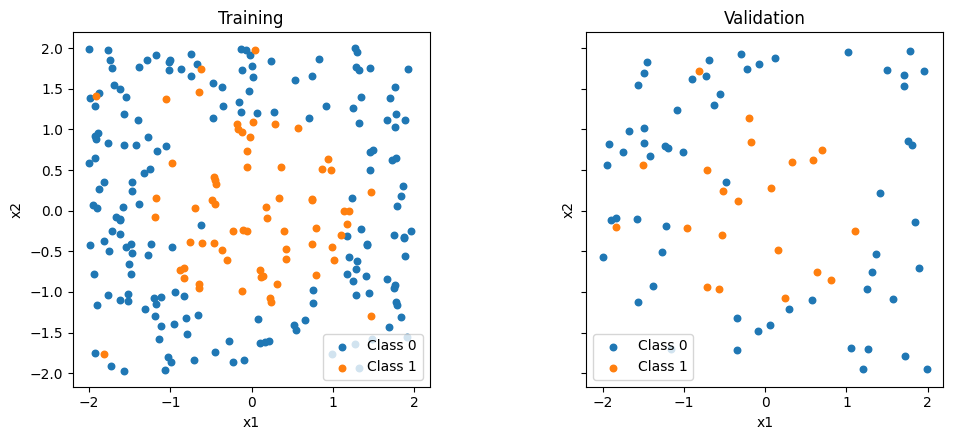

In [9]:
rng = random.Random(14)
X_class, y_class = [], []

# Generate 320 data points and label them based on region inside/outside a circle.
for i in range(320):
    x1, x2 = rng.uniform(-2, 2), rng.uniform(-2, 2)
    label = int(x1*x1 + x2*x2 < 1.45)
    if rng.random() < 0.05:
        label = 1 - label
    X_class.append([x1, x2])
    y_class.append(label)
X_ct, y_ct, X_cv, y_cv = split_data(X_class, y_class, seed=14)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, X, y, title in [(axes[0], X_ct, y_ct, 'Training'), (axes[1], X_cv, y_cv, 'Validation')]:
    for label in [0, 1]:
        points = [x for x, target in zip(X, y) if target == label]
        ax.scatter([x[0] for x in points], [x[1] for x in points], label=f'Class {label}', s=22)
    ax.set(title=title, xlabel='x1', ylabel='x2', aspect='equal')
    ax.legend()
plt.tight_layout()
plt.show()

## A2. Build and train: 2 inputs → 6 hidden neurons → 1 output

The following cell makes the learning sequence explicit: construct parameters, then pass them to the training function.

Epoch    1/1800 | training: 0.751726 | validation: 0.777608
Epoch    2/1800 | training: 0.740128 | validation: 0.764415
Epoch    3/1800 | training: 0.729442 | validation: 0.752223
Epoch    4/1800 | training: 0.719601 | validation: 0.740953
Epoch    5/1800 | training: 0.710536 | validation: 0.730536
Epoch    6/1800 | training: 0.702188 | validation: 0.720905
Epoch    7/1800 | training: 0.694499 | validation: 0.711997
Epoch    8/1800 | training: 0.687416 | validation: 0.703757
Epoch    9/1800 | training: 0.680891 | validation: 0.696131
Epoch   10/1800 | training: 0.674879 | validation: 0.689070
Epoch   11/1800 | training: 0.669336 | validation: 0.682530
Epoch   12/1800 | training: 0.664226 | validation: 0.676469
Epoch   13/1800 | training: 0.659512 | validation: 0.670849
Epoch   14/1800 | training: 0.655161 | validation: 0.665635
Epoch   15/1800 | training: 0.651145 | validation: 0.660794
Epoch   16/1800 | training: 0.647435 | validation: 0.656296
Epoch   17/1800 | training: 0.644006 | v

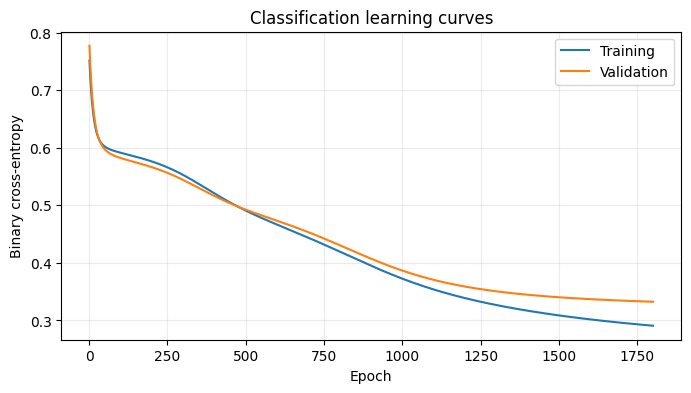

In [10]:
w_class, b_class, v_class, c_class = build_model(2, 6, seed=5)
w_class, b_class, v_class, c_class, class_training, class_validation = train_model(
    X_ct, y_ct, X_cv, y_cv, w_class, b_class, v_class, c_class,
    task='classification', epochs=1800, learning_rate=0.12
)
plot_losses(class_training, class_validation, 'Classification learning curves', 'Binary cross-entropy')

## A3. Evaluate both splits

Class 1 is positive; the decision threshold is 0.5.

$$\mathrm{accuracy}=\frac{TP+TN}{N},\quad \mathrm{precision}=\frac{TP}{TP+FP},\quad \mathrm{recall}=\frac{TP}{TP+FN}.$$

$$\mathrm{specificity}=\frac{TN}{TN+FP},\quad F_1=\frac{2\,\mathrm{precision}\,\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}.$$

The implementation reports zero when a metric's denominator is zero.

In [11]:
metrics_train = classification_metrics(X_ct, y_ct, w_class, b_class, v_class, c_class)
metrics_val = classification_metrics(X_cv, y_cv, w_class, b_class, v_class, c_class)
show_classification_table(metrics_train, metrics_val)

| Metric | Training | Validation |
|---|---:|---:|
| Accuracy | 0.8875 | 0.8750 |
| Precision | 0.9545 | 0.8667 |
| Recall | 0.6269 | 0.6190 |
| Specificity | 0.9884 | 0.9661 |
| F1 | 0.7568 | 0.7222 |
| TP | 42 | 13 |
| TN | 171 | 57 |
| FP | 2 | 2 |
| FN | 25 | 8 |

## A4. Visualize the learned boundary

The background is the estimated probability of class 1. The black contour is the 0.5 decision boundary. Circles show training data; outlined squares show validation data.

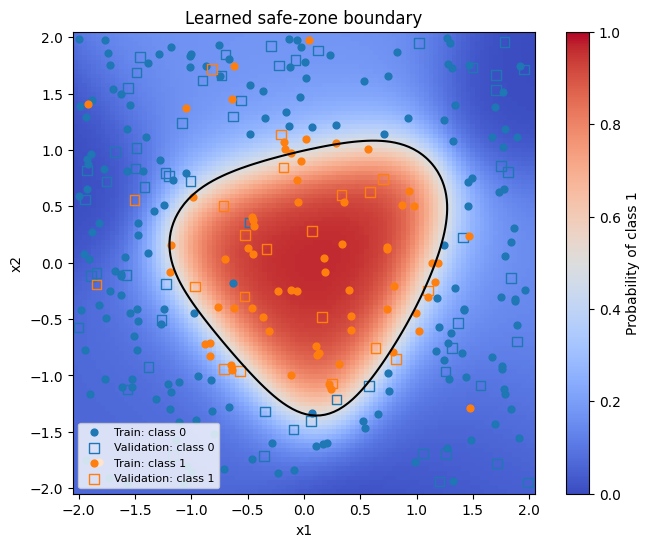

In [12]:
coordinates = [-2.05 + 4.1*i/99 for i in range(100)]
probabilities = []
for x2 in coordinates:
    probabilities.append([forward_propagation([x1, x2], w_class, b_class, v_class, c_class, 'classification')[0]
                          for x1 in coordinates])
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(probabilities, origin='lower', extent=(-2.05, 2.05, -2.05, 2.05), cmap='coolwarm', vmin=0, vmax=1)
ax.contour(coordinates, coordinates, probabilities, levels=[0.5], colors='black')
for label, color in [(0, 'tab:blue'), (1, 'tab:orange')]:
    for X, y, split in [(X_ct, y_ct, 'Train'), (X_cv, y_cv, 'Validation')]:
        points = [x for x, target in zip(X, y) if target == label]
        ax.scatter([x[0] for x in points], [x[1] for x in points], s=24 if split == 'Train' else 48,
                   marker='o' if split == 'Train' else 's',
                   facecolors=color if split == 'Train' else 'none', edgecolors=color,
                   label=f'{split}: class {label}')
ax.set(title='Learned safe-zone boundary', xlabel='x1', ylabel='x2')
ax.legend(fontsize=8)
fig.colorbar(image, ax=ax, label='Probability of class 1')
plt.show()

# Example B — Nonlinear regression
## B1. Generate and inspect noisy calibration observations

The input is one sensor measurement; the target is a continuous response. We plot only the observed points, not the noise-free generating curve. Both architectures will use exactly the same training and validation split.

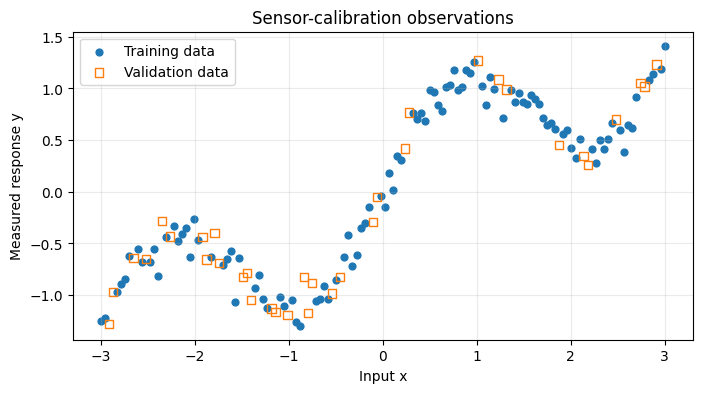

In [13]:
rng = random.Random(31)
X_reg, y_reg = [], []
for i in range(140):
    x = -3 + 6*i/139
    X_reg.append([x])
    y_reg.append(0.5*x + 0.7*math.sin(2*x) + rng.gauss(0, 0.11))
X_rt, y_rt, X_rv, y_rv = split_data(X_reg, y_reg, seed=31)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter([x[0] for x in X_rt], y_rt, label='Training data', s=24)
ax.scatter([x[0] for x in X_rv], y_rv, label='Validation data', marker='s', facecolors='none', edgecolors='tab:orange')
ax.set(title='Sensor-calibration observations', xlabel='Input x', ylabel='Measured response y')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## B2. Baseline architecture: 1 input → 2 hidden neurons → 1 output

Start with a small hidden layer. The output is linear and the loss is half MSE. Inspect the fit and losses before comparing it with a larger hidden layer.

Epoch    1/2000 | training: 0.275186 | validation: 0.369687
Epoch    2/2000 | training: 0.253103 | validation: 0.338833
Epoch    3/2000 | training: 0.234220 | validation: 0.312274
Epoch    4/2000 | training: 0.218041 | validation: 0.289378
Epoch    5/2000 | training: 0.204120 | validation: 0.269568
Epoch    6/2000 | training: 0.192072 | validation: 0.252341
Epoch    7/2000 | training: 0.181581 | validation: 0.237275
Epoch    8/2000 | training: 0.172388 | validation: 0.224025
Epoch    9/2000 | training: 0.164284 | validation: 0.212307
Epoch   10/2000 | training: 0.157099 | validation: 0.201891
Epoch   11/2000 | training: 0.150697 | validation: 0.192589
Epoch   12/2000 | training: 0.144967 | validation: 0.184246
Epoch   13/2000 | training: 0.139816 | validation: 0.176735
Epoch   14/2000 | training: 0.135171 | validation: 0.169950
Epoch   15/2000 | training: 0.130967 | validation: 0.163804
Epoch   16/2000 | training: 0.127153 | validation: 0.158220
Epoch   17/2000 | training: 0.123683 | v

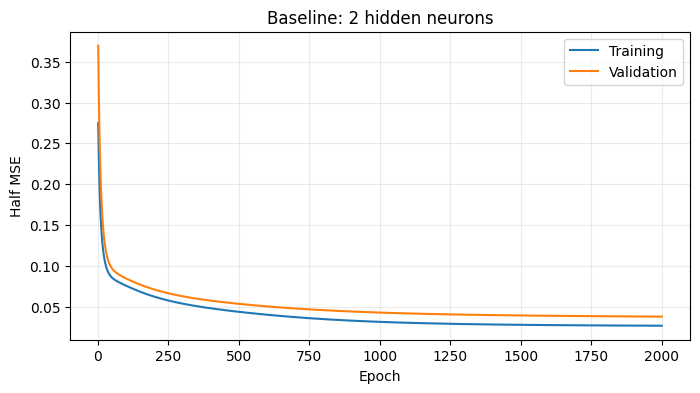

In [14]:
w_small, b_small, v_small, c_small = build_model(1, 2, seed=9)
w_small, b_small, v_small, c_small, small_training, small_validation = train_model(
    X_rt, y_rt, X_rv, y_rv, w_small, b_small, v_small, c_small,
    task='regression', epochs=2000, learning_rate=0.05
)
plot_losses(small_training, small_validation, 'Baseline: 2 hidden neurons', 'Half MSE')

## B3. Plot the baseline estimate

Compare the estimated curve with the observed training and validation points. The function below is only a plotting helper; it does not fit a model.

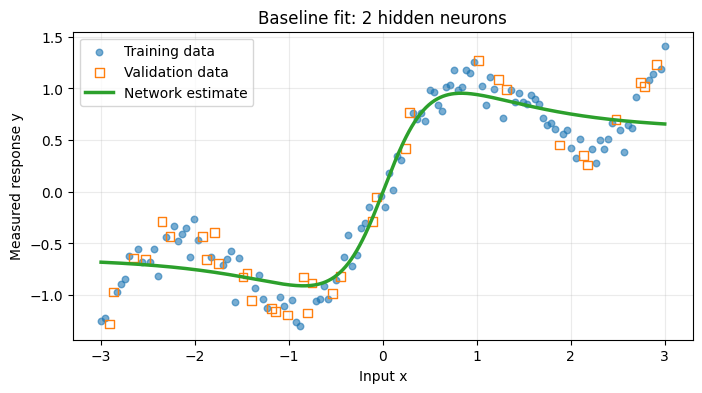

In [15]:
def plot_regression_fit(ax, X_train, y_train, X_val, y_val, w, b, v, c, title):
    """Overlay a model estimate on observations, without showing the generating function."""
    curve_x = [-3 + 6*i/399 for i in range(400)]
    curve_y = [forward_propagation([x], w, b, v, c, 'regression')[0] for x in curve_x]
    ax.scatter([x[0] for x in X_train], y_train, s=22, alpha=0.6, label='Training data')
    ax.scatter([x[0] for x in X_val], y_val, s=40, facecolors='none', edgecolors='tab:orange', marker='s', label='Validation data')
    ax.plot(curve_x, curve_y, color='tab:green', linewidth=2.5, label='Network estimate')
    ax.set(title=title, xlabel='Input x', ylabel='Measured response y')
    ax.grid(alpha=0.25)
    ax.legend()

fig, ax = plt.subplots(figsize=(8, 4))
plot_regression_fit(ax, X_rt, y_rt, X_rv, y_rv, w_small, b_small, v_small, c_small, 'Baseline fit: 2 hidden neurons')
plt.show()

## B4. Larger architecture: 1 input → 8 hidden neurons → 1 output

Increase only the number of hidden neurons. Keep the split, learning rate, epoch count, and initialization seed fixed. With a different architecture the random draws do not give an identical initialization; this is a reproducible demonstration, not an average over repeated trials.

The additional hidden responses give the output more components with which to model changing curvature. Check whether validation loss improves rather than assuming that a larger network is always better.

Epoch    1/2000 | training: 0.233688 | validation: 0.193955
Epoch    2/2000 | training: 0.188027 | validation: 0.157678
Epoch    3/2000 | training: 0.158006 | validation: 0.134796
Epoch    4/2000 | training: 0.138101 | validation: 0.120373
Epoch    5/2000 | training: 0.124781 | validation: 0.111305
Epoch    6/2000 | training: 0.115769 | validation: 0.105627
Epoch    7/2000 | training: 0.109591 | validation: 0.102095
Epoch    8/2000 | training: 0.105289 | validation: 0.099919
Epoch    9/2000 | training: 0.102236 | validation: 0.098598
Epoch   10/2000 | training: 0.100022 | validation: 0.097813
Epoch   11/2000 | training: 0.098378 | validation: 0.097364
Epoch   12/2000 | training: 0.097125 | validation: 0.097122
Epoch   13/2000 | training: 0.096142 | validation: 0.097007
Epoch   14/2000 | training: 0.095352 | validation: 0.096966
Epoch   15/2000 | training: 0.094698 | validation: 0.096968
Epoch   16/2000 | training: 0.094144 | validation: 0.096993
Epoch   17/2000 | training: 0.093664 | v

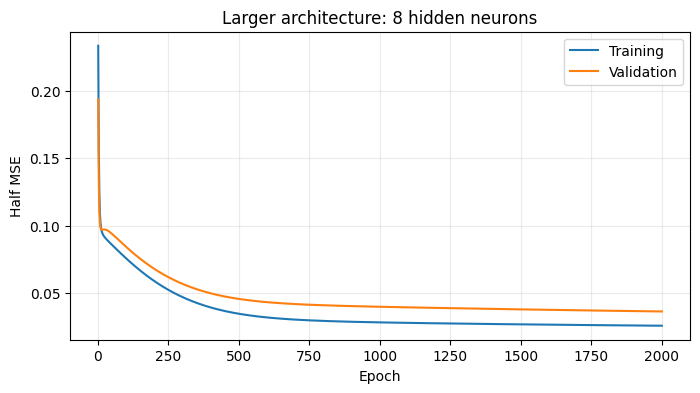

In [16]:
w_large, b_large, v_large, c_large = build_model(1, 8, seed=9)
w_large, b_large, v_large, c_large, large_training, large_validation = train_model(
    X_rt, y_rt, X_rv, y_rv, w_large, b_large, v_large, c_large,
    task='regression', epochs=2000, learning_rate=0.05
)
plot_losses(large_training, large_validation, 'Larger architecture: 8 hidden neurons', 'Half MSE')

## B5. Compare both architectures

Use shared axes to compare the two fits fairly. The table reports ordinary MSE (twice the loss used during training) and RMSE, which is in the target's units. Validation results have informed our architecture comparison, so they are not an independent final test result.

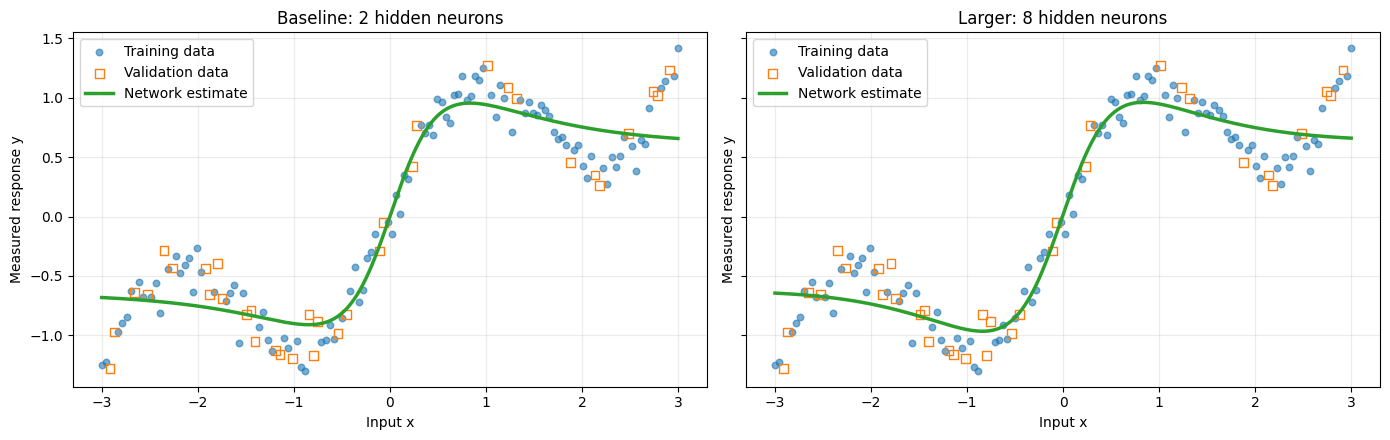

| Architecture | Training MSE | Validation MSE | Training RMSE | Validation RMSE |
|---|---:|---:|---:|---:|
| 2 hidden neurons | 0.05305 | 0.07536 | 0.23033 | 0.27452 |
| 8 hidden neurons | 0.05107 | 0.07228 | 0.22599 | 0.26885 |

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True, sharey=True)
plot_regression_fit(axes[0], X_rt, y_rt, X_rv, y_rv, w_small, b_small, v_small, c_small, 'Baseline: 2 hidden neurons')
plot_regression_fit(axes[1], X_rt, y_rt, X_rv, y_rv, w_large, b_large, v_large, c_large, 'Larger: 8 hidden neurons')
plt.tight_layout()
plt.show()

rows = ['| Architecture | Training MSE | Validation MSE | Training RMSE | Validation RMSE |',
        '|---|---:|---:|---:|---:|']
for name, tr, va in [('2 hidden neurons', small_training[-1], small_validation[-1]),
                     ('8 hidden neurons', large_training[-1], large_validation[-1])]:
    rows.append(f'| {name} | {2*tr:.5f} | {2*va:.5f} | {math.sqrt(2*tr):.5f} | {math.sqrt(2*va):.5f} |')
display(Markdown('\n'.join(rows)))